| 指标 | 含义 | 越好方向 |
|---|---|---|
| MAPE | 需求预测平均偏差占真实值的百分比 | 越低越好 |
| MAE | 需求预测平均相差多少 MW | 越低越好 |
| Accuracy | 电价方向预测正确的比例 | 越高越好 |
| Balanced Accuracy | 两个类别召回率的平均值，避免多数类主导结果 | 越高越好 |

In [8]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import dayahead as da
from sklearn.ensemble import HistGradientBoostingRegressor

ROOT = Path.cwd().parent
assert (ROOT / "harness" / "dayahead.py").is_file(), (
    "请确认当前 notebook 位于项目的 project 文件夹。"
)

sys.path.insert(0, str(ROOT / "harness"))

df = da.load_dataset(
    ROOT / "data" / "nem_weather_halfhourly_2010_2026.csv"
)

print("数据形状：", df.shape)
print("项目根目录：", ROOT)

数据形状： (295104, 18)
项目根目录： /Users/haruka/Desktop/UNSW/9417/comp9417_project_kit


In [11]:
#评估函数,把预测与真实答案交给这个评分器，它就计算四项指标：MAPE、MAE、Accuracy、Balanced Accuracy。它还可以分别统计每个月、每年的成绩
def evaluate_predictions(truth, pred, frequency=None):
    """
    truth、pred：
        以时间戳为索引，包含以下两列：
        nsw_demand_mw、nsw_price_up

    frequency：
        None：整个时期
        "M"：按交易日所属月份
        "Y"：按交易日所属年份
    """
    columns = ["nsw_demand_mw", "nsw_price_up"]

    if not truth.index.equals(pred.index):
        raise ValueError("真实值和预测值的时间索引不一致。")

    if truth.empty:
        raise ValueError("没有可评估的数据。")

    for name, frame in [("truth", truth), ("pred", pred)]:
        if not np.isfinite(frame[columns].to_numpy(dtype=float)).all():
            raise ValueError(f"{name} 含有缺失值或无穷值。")
        if not frame["nsw_price_up"].isin([0, 1]).all():
            raise ValueError(f"{name} 的分类值必须为 0 或 1。")

    if frequency is None:
        return pd.DataFrame(
            [da.score(truth, pred)], index=["overall"]
        )

    if frequency not in ("M", "Y"):
        raise ValueError('frequency 必须是 None、"M" 或 "Y"。')

    periods = da.market_day(truth.index).to_period(frequency)
    rows = {}

    for period in periods.unique().sort_values():
        mask = periods == period
        rows[str(period)] = da.score(
            truth.loc[mask], pred.loc[mask]
        )

    return pd.DataFrame.from_dict(rows, orient="index")

In [12]:
target_day = pd.Timestamp("2014-01-08")
truth = da.targets(df, target_day)

print(evaluate_predictions(truth, truth.copy()).round(4))

         MAPE  MAE  BalAcc    Acc
overall   0.0  0.0   100.0  100.0


In [13]:
# 按交易日计算均价，并将其对应到当天每一行
market_days = da.market_day(df.index)
daily_mean = df["nsw_price"].groupby(market_days).transform("mean")

# 每天固定 48 行，因此移动 48 行就是前一天同一时段
previous_day_mean = daily_mean.shift(48)

# 统一评估区间：排除最初 7 天
evaluation_index = df.index[48 * 7:]

truth_all = pd.DataFrame(
    {
        "nsw_demand_mw": df["nsw_demand"],
        "nsw_price_up": (
            df["nsw_price"] > previous_day_mean
        ).astype(int),
    }
).loc[evaluation_index]


def make_baseline(lag_days):
    return pd.DataFrame(
        {
            "nsw_demand_mw": df["nsw_demand"].shift(48 * lag_days),
            # 两种基线都与前一天均价比较
            "nsw_price_up": (
                df["nsw_price"].shift(48 * lag_days)
                > previous_day_mean
            ).astype(int),
        }
    ).loc[evaluation_index]


baseline_yesterday = make_baseline(lag_days=1)
baseline_lastweek = make_baseline(lag_days=7)

print("评估行数：", len(truth_all))
print("起始时段：", truth_all.index.min())
print("结束时段：", truth_all.index.max())

评估行数： 294768
起始时段： 2010-01-08 00:30:00
结束时段： 2026-11-01 00:00:00


In [14]:
baselines = {
    "yesterday": baseline_yesterday,
    "last_week": baseline_lastweek,
}

baseline_yearly = pd.concat(
    {
        name: evaluate_predictions(truth_all, pred, frequency="Y")
        for name, pred in baselines.items()
    },
    names=["baseline", "year"],
)

baseline_monthly = pd.concat(
    {
        name: evaluate_predictions(truth_all, pred, frequency="M")
        for name, pred in baselines.items()
    },
    names=["baseline", "month"],
)

print("2014 年两种基线的成绩：")
display(
    baseline_yearly.xs("2014", level="year").round(2)
)

print("昨天同一时段基线的前 5 个月成绩：")
display(
    baseline_monthly.loc["yesterday"].head().round(2)
)

2014 年两种基线的成绩：


,MAPE,MAE,BalAcc,Acc
baseline,,,,
yesterday,4.93,394.42,73.99,73.90
last_week,4.93,401.26,74.28,74.25


昨天同一时段基线的前 5 个月成绩：


,MAPE,MAE,BalAcc,Acc
month,,,,
2010-01,7.26,685.59,82.33,82.73
2010-02,5.99,573.51,79.28,79.39
2010-03,4.33,389.20,83.58,83.60
2010-04,4.48,367.68,81.24,81.04
2010-05,4.43,390.74,72.59,77.49


/var/folders/98/44n_mnx513s57z0s0f_87mr40000gn/T/ipykernel_61123/301829164.py:13: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  eda["day"].dt.dayofweek < 5, "Weekday", "Weekend"


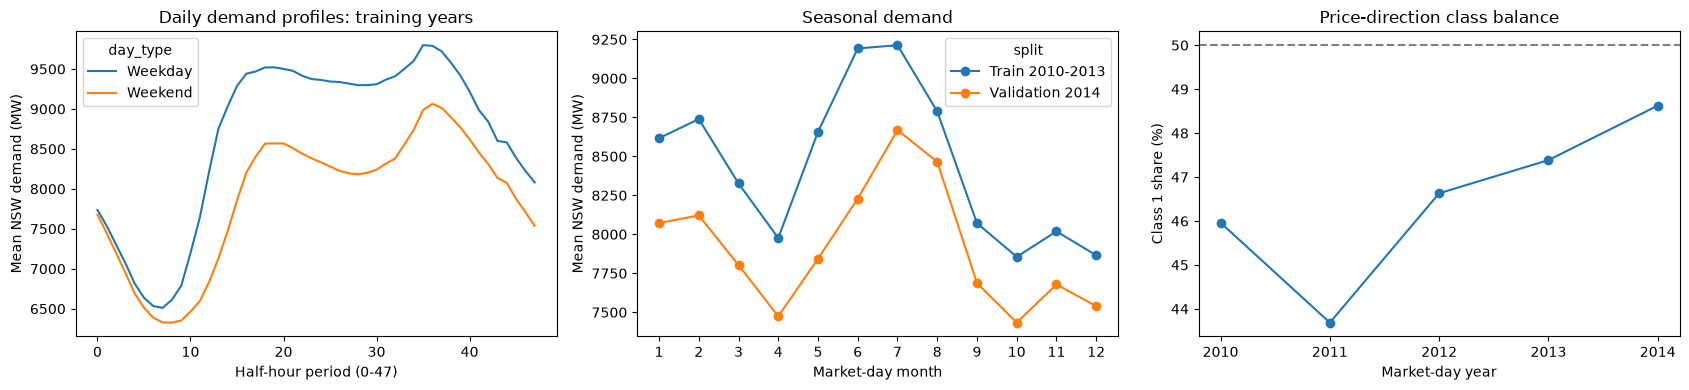

,n_halfhours,class_1_share_pct
year,,
2010,17184,45.96
2011,17520,43.69
2012,17568,46.63
2013,17520,47.39
2014,17520,48.62


In [16]:
import matplotlib.pyplot as plt

# 使用交易日生成日历信息，确保午夜归属正确
eda = pd.DataFrame(index=df.index)
eda["day"] = da.market_day(df.index)
eda["year"] = eda["day"].dt.year
eda["month"] = eda["day"].dt.month
eda["period"] = (
    (df.index - pd.Timedelta(minutes=30)).hour * 2
    + (df.index - pd.Timedelta(minutes=30)).minute // 30
)
eda["day_type"] = np.where(
    eda["day"].dt.dayofweek < 5, "Weekday", "Weekend"
)
eda["demand_mw"] = df["nsw_demand"]

# 按时间索引对齐；最初七天因无上周基线，标签暂为空
eda["y_up"] = truth_all["nsw_price_up"]

initial = eda.loc[eda["year"].between(2010, 2014)].copy()
training = initial.loc[initial["year"] <= 2013].copy()

# 1. 训练期：工作日与周末的日内需求曲线
daily_profile = (
    training.groupby(["period", "day_type"])["demand_mw"]
    .mean()
    .unstack("day_type")
)

# 2. 分开统计训练期和验证期的季节性
initial["split"] = np.where(
    initial["year"] <= 2013, "Train 2010-2013", "Validation 2014"
)

seasonal_demand = (
    initial.groupby(["month", "split"])["demand_mw"]
    .mean()
    .unstack("split")
)

# 3. 每年类别 1 的比例
class_share = initial.groupby("year")["y_up"].agg(
    class_1_share="mean",
    n_halfhours="count",
)
class_share["class_1_share_pct"] = (
    class_share["class_1_share"] * 100
)

# 绘图
fig, axes = plt.subplots(1, 3, figsize=(17, 4))

daily_profile.plot(ax=axes[0])
axes[0].set_title("Daily demand profiles: training years")
axes[0].set_xlabel("Half-hour period (0-47)")
axes[0].set_ylabel("Mean NSW demand (MW)")

seasonal_demand.plot(ax=axes[1], marker="o")
axes[1].set_title("Seasonal demand")
axes[1].set_xlabel("Market-day month")
axes[1].set_ylabel("Mean NSW demand (MW)")
axes[1].set_xticks(range(1, 13))

class_share["class_1_share_pct"].plot(
    ax=axes[2], marker="o"
)
axes[2].axhline(50, color="gray", linestyle="--")
axes[2].set_title("Price-direction class balance")
axes[2].set_xlabel("Market-day year")
axes[2].set_ylabel("Class 1 share (%)")
axes[2].set_xticks(range(2010, 2015))

plt.tight_layout()
plt.show()

display(class_share[["n_halfhours", "class_1_share_pct"]].round(2))

In [25]:
#Ridge Regression
#创建模型输入特征 X 和真实答案 y
ridge_data = pd.DataFrame(index=df.index)
ridge_data["day"] = da.market_day(df.index)
# 每天第几个半小时：0 ~ 47
interval_start = df.index - pd.Timedelta(minutes=30)
ridge_data["period"] = (
    interval_start.hour * 2
    + interval_start.minute // 30
)
# 将半小时时段转换为周期特征
ridge_data["period_sin"] = np.sin(
    2 * np.pi * ridge_data["period"] / 48
)
ridge_data["period_cos"] = np.cos(
    2 * np.pi * ridge_data["period"] / 48
)
# 昨天同一时刻的电力需求
ridge_data["demand_lag1"] = df["nsw_demand"].shift(48)
# 上周同一时刻的电力需求
ridge_data["demand_lag7"] = df["nsw_demand"].shift(48 * 7)
# 明天的天气：项目规定可以使用
for c in da.WEATHER_COLS:
    ridge_data[c] = df[c]
# 星期几：0=周一，6=周日
ridge_data["dayofweek"] = ridge_data["day"].dt.dayofweek
# 月份
ridge_data["month"] = ridge_data["day"].dt.month
# 真实答案：NSW 电力需求
ridge_data["y_demand"] = df["nsw_demand"]
# 删除前七天，保证历史特征完整
ridge_data = ridge_data.iloc[48 * 7:].dropna()
ridge_data.head()
# 将星期几转换为周期特征
ridge_data["dow_sin"] = np.sin(
    2 * np.pi * ridge_data["dayofweek"] / 7
)
ridge_data["dow_cos"] = np.cos(
    2 * np.pi * ridge_data["dayofweek"] / 7
)
# 将月份转换为周期特征
ridge_data["month_sin"] = np.sin(
    2 * np.pi * (ridge_data["month"] - 1) / 12
)
ridge_data["month_cos"] = np.cos(
    2 * np.pi * (ridge_data["month"] - 1) / 12
)

#创建X和Y⭐️
feature_cols = [
    "demand_lag1",
    "demand_lag7",
    "period_sin",
    "period_cos",
    "dow_sin",
    "dow_cos",
    "month_sin",
    "month_cos",
] + list(da.WEATHER_COLS)

X = ridge_data[feature_cols]
display(X.head())
y = ridge_data["y_demand"]

print("X shape:", X.shape)
print("y shape:", y.shape)

#按时间划分训练集（2010–2013）和验证集（2014）
# 按交易日所属年份划分，避免午夜被分到错误年份
sample_years = ridge_data["day"].dt.year

train_mask = sample_years.between(2010, 2013)
valid_mask = sample_years == 2014

X_train = X.loc[train_mask]
y_train = y.loc[train_mask]

X_valid = X.loc[valid_mask]
y_valid = y.loc[valid_mask]

print("训练集：", X_train.shape)
print("验证集：", X_valid.shape)
# print("训练交易日范围：",
#       ridge_data.loc[train_mask, "day"].min(),
#       "至",
#       ridge_data.loc[train_mask, "day"].max())
# print("验证交易日范围：",
#       ridge_data.loc[valid_mask, "day"].min(),
#       "至",
#       ridge_data.loc[valid_mask, "day"].max())


from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Pipeline 确保标准化只在 fit 时学习训练集统计量
ridge_model = make_pipeline(
    StandardScaler(),
    Ridge(alpha=1.0),
)

ridge_model.fit(X_train, y_train)

# predict 只使用训练时已经学到的参数
ridge_valid_pred = pd.Series(
    ridge_model.predict(X_valid),
    index=X_valid.index,
    name="ridge_demand_mw",
)

# 三种方法均使用完全相同的验证时段和真实答案
predictions = {
    "Yesterday baseline": baseline_yesterday.loc[
        X_valid.index, "nsw_demand_mw"
    ],
    "Last-week baseline": baseline_lastweek.loc[
        X_valid.index, "nsw_demand_mw"
    ],
    "Ridge (alpha=1)": ridge_valid_pred,
}

demand_validation_results = pd.DataFrame.from_dict(
    {
        name: {
            "MAPE (%)": da.mape(y_valid, pred),
            "MAE (MW)": da.mae(y_valid, pred),
        }
        for name, pred in predictions.items()
    },
    orient="index",
)

display(demand_validation_results.round(3))



/var/folders/98/44n_mnx513s57z0s0f_87mr40000gn/T/ipykernel_61123/3193132507.py:26: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  ridge_data["dayofweek"] = ridge_data["day"].dt.dayofweek


,demand_lag1,demand_lag7,period_sin,period_cos,dow_sin,dow_cos,month_sin,month_cos,syd_temp,syd_rh,syd_cloud,syd_solar,mel_temp,mel_rh,mel_cloud,mel_solar,bne_temp,bne_rh,bne_cloud,bne_solar
timestamp,,,,,,,,,,,,,,,,,,,,
2010-01-08 00:30:00,7433.46,7809.31,0.000000,1.000000,-0.433884,-0.900969,0.0,1.0,20.95,74.5,99.5,0.0,15.20,87.0,0.0,0.0,22.90,88.0,98.5,0.0
2010-01-08 01:00:00,7216.30,7483.69,0.130526,0.991445,-0.433884,-0.900969,0.0,1.0,20.90,75.0,100.0,0.0,14.70,89.0,0.0,0.0,22.70,88.0,99.0,0.0
2010-01-08 01:30:00,6940.48,7117.23,0.258819,0.965926,-0.433884,-0.900969,0.0,1.0,20.85,75.5,100.0,0.0,14.00,91.5,0.0,0.0,22.35,89.5,99.0,0.0
2010-01-08 02:00:00,6692.82,6812.03,0.382683,0.923880,-0.433884,-0.900969,0.0,1.0,20.80,76.0,100.0,0.0,13.30,94.0,0.0,0.0,22.00,91.0,99.0,0.0
2010-01-08 02:30:00,6477.56,6544.33,0.500000,0.866025,-0.433884,-0.900969,0.0,1.0,20.80,76.5,100.0,0.0,13.25,94.0,0.0,0.0,21.95,92.0,99.5,0.0


X shape: (294768, 20)
y shape: (294768,)
训练集： (69792, 20)
验证集： (17520, 20)


,MAPE (%),MAE (MW)
Yesterday baseline,4.935,394.422
Last-week baseline,4.934,401.256
Ridge (alpha=1),3.948,315.190


In [26]:
#Hyperparameter Tuning（超参数调优）
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_percentage_error
import pandas as pd

alphas = [0.01, 0.1, 1, 10, 100, 1000]

results = []

for alpha in alphas:

    model = make_pipeline(
        StandardScaler(),
        Ridge(alpha=alpha)
    )

    # 2010–2013 训练
    model.fit(X_train, y_train)

    # 2014 验证
    pred = model.predict(X_valid)

    mape = mean_absolute_percentage_error(
        y_valid, pred
    ) * 100

    results.append({
        "alpha": alpha,
        "MAPE": mape
    })

ridge_tuning = pd.DataFrame(results)

display(ridge_tuning.sort_values("MAPE"))

best_alpha = ridge_tuning.loc[
    ridge_tuning["MAPE"].idxmin(),
    "alpha"
]

print("Best alpha:", best_alpha)

,alpha,MAPE
3,10.00,3.947941
2,1.00,3.947946
1,0.10,3.947947
0,0.01,3.947947
4,100.00,3.947964
5,1000.00,3.954621


Best alpha: 10.0


## Gradient Boosting Regression

In [ ]:
# 1. 创建模型
gb_model = HistGradientBoostingRegressor(
    learning_rate=0.05,
    max_iter=200,
    max_leaf_nodes=31,
    l2_regularization=1.0,
    early_stopping=False,
    random_state=42
)
# 2. 训练模型 (2010–2013)
gb_model.fit(X_train, y_train)

# 3. 预测 (2014)
y_pred_gb = gb_model.predict(X_valid)